# Notebook 06: Modelos con variables meteorológicas

Se incorporan las variables meteorológicas preprocesadas en el notebook 05 a los tres mejores modelos univariantes del notebook 04: lineal, Random Forest y XGBoost, todos en estrategia recursiva y con la hora del día. Cada uno se compara contra su versión sin meteorología con el mismo protocolo de backtesting. Se evalúan los tres porque en el notebook 04 sus diferencias fueron pequeñas y dependían de la métrica: el lineal obtuvo el menor RMSE y Random Forest el menor MAE.

## 1. Configuración

In [1]:
!pip install -q skforecast==0.24.0
import random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from skforecast.recursive import ForecasterRecursive, ForecasterEquivalentDate
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
import skforecast, sklearn, xgboost
from sklearn.ensemble import RandomForestRegressor
SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("skforecast", skforecast.__version__, "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 517.7/517.7 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.7 MB/s eta 0:00:00
skforecast 0.24.0 | sklearn 1.6.1 | xgboost 3.4.1


## 2. Datos
Se cargan la serie de PM2.5 de Curva de Maroñas en entrenamiento (desarrollo) y las variables meteorológicas, alineadas hora a hora con la serie. También se construye la hora del día: en forma cíclica (seno y coseno) para el modelo lineal y como número entero para XGBoost, igual que en el notebook 04.

In [2]:
REPO = "https://raw.githubusercontent.com/trajano-carballo/paa-pronostico-pm25-montevideo/main/data/processed/"
pm = pd.read_csv(REPO + "pm25_horario_preprocesado.csv")
met = pd.read_csv(REPO + "meteorologia_horaria_preprocesada.csv")
for d in (pm, met):
    d["hora"] = pd.to_datetime(d["hora"], utc=True).dt.tz_convert("America/Montevideo")

dev = (pm[(pm["estacion"] == "Curva de Maroñas") & (pm["particion"] == "desarrollo")]
       .set_index("hora").sort_index().asfreq("h"))
y_modelo, y_real = dev["pm25_modelo"], dev["pm25"]

METEO = ["temperatura", "humedad", "velocidad_viento_ms", "viento_u", "viento_v", "visibilidad_km"]
meteo = met.set_index("hora").reindex(y_modelo.index)[METEO]

idx = y_modelo.index
hora_cic = pd.DataFrame({"hora_sin": np.sin(2 * np.pi * idx.hour / 24),
                         "hora_cos": np.cos(2 * np.pi * idx.hour / 24)}, index=idx)
hora_int = pd.DataFrame({"hora": idx.hour}, index=idx)
print(f"Horas: {len(dev)} | horas con algún faltante meteorológico: {meteo.isna().any(axis=1).sum()}")

Horas: 17544 | horas con algún faltante meteorológico: 10


## 3. Protocolo de backtesting y casos comunes
Se mantiene exactamente el protocolo del notebook 04: `steps=24`, `refit=False`, `fold_stride=7`, entrenamiento con 2024 y evaluación en 2025, y orígenes con ventana de 168 h completa. Se agrega una condición: la meteorología debe estar completa en las 24 horas pronosticadas, porque los modelos la usan como entrada en cada paso. Así todos los modelos, con y sin meteorología, se comparan sobre los mismos casos.

In [3]:
STEPS, FOLD_STRIDE = 24, 7
N_INICIAL = int((idx < pd.Timestamp("2025-01-01", tz="America/Montevideo")).sum())
cv = TimeSeriesFold(steps=STEPS, initial_train_size=N_INICIAL, refit=False, fold_stride=FOLD_STRIDE)

L_MAX = 168
ventana_ok = y_modelo.notna().astype(int).rolling(L_MAX).sum().eq(L_MAX)
meteo_ok = meteo.notna().all(axis=1)

## 4. Funciones de evaluación
Mismas funciones que en el notebook 04, con la condición adicional de meteorología completa en el horizonte.

In [4]:
def sin_metrica(y_true, y_pred):
    return 0.0

_, p0 = backtesting_forecaster(ForecasterEquivalentDate(offset=24), y=y_modelo, cv=cv,
                               metric=sin_metrica, show_progress=False, suppress_warnings=True)
base = p0[["fold"]].copy()
base["h"] = base.groupby("fold").cumcount() + 1
base["origen"] = base.index - pd.to_timedelta(base["h"], unit="h")
base["real"] = y_real.reindex(base.index).to_numpy()
base["meteo_ok"] = (pd.Series(meteo_ok.reindex(base.index).to_numpy(), index=base.index)
                    .groupby(base["fold"].to_numpy()).transform("all").to_numpy())

def backtest(modelos, exogs=None):
    preds = {}
    for nombre, f in modelos.items():
        t = time.time()
        _, p = backtesting_forecaster(f, y=y_modelo, exog=(exogs or {}).get(nombre), cv=cv,
                                      metric=sin_metrica, show_progress=False, suppress_warnings=True)
        assert (p.index == base.index).all()
        preds[nombre] = p["pred"]
        print(f"{nombre}: {time.time() - t:.0f} s")
    return preds

def tabla_comun(preds):
    T = base.copy()
    for n, p in preds.items():
        T[n] = p.to_numpy()
    cols = list(preds)
    T["comun"] = (ventana_ok.reindex(T["origen"]).to_numpy() & T["meteo_ok"]
                  & T["real"].notna() & T[cols].notna().all(axis=1))
    return T, cols

def metricas(T, cols):
    C = T[T["comun"]]
    e = C[cols].sub(C["real"], axis=0)
    print(f"Casos comunes: {len(C)} de {len(T)} ({len(C)/len(T):.1%})")
    return pd.DataFrame({"MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean())}).round(2)

def por_horizonte(T, cols, metrica="MAE"):
    C = T[T["comun"]]
    e = C[cols].sub(C["real"], axis=0)
    g = (e.abs() if metrica == "MAE" else e**2).groupby(C["h"]).mean()
    return g if metrica == "MAE" else np.sqrt(g)

## 5. Incorporación de las variables meteorológicas
Se agregan las variables de forma incremental, empezando por el viento, que es la que más se relaciona con la dispersión de contaminantes:
- **viento:** velocidad y componentes `viento_u` y `viento_v`;
- **viento + temperatura + humedad;**
- **todas:** las anteriores más la visibilidad.

Cada conjunto se evalúa en los tres modelos, con los rezagos e hiperparámetros elegidos en el notebook 04, y se compara contra su versión sin meteorología y contra la persistencia estacional.

In [5]:
# Configuración elegida en el notebook 04 para cada familia
CONFIG = {
    "Lineal": {"est": lambda: LinearRegression(),
               "lags": list(range(1, 25)) + [48, 168], "hora": hora_cic},
    "RF":     {"est": lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1, max_depth=4,
                                                    max_features=0.3, min_samples_leaf=1, n_estimators=200),
               "lags": [1, 2, 3, 24, 48], "hora": hora_int},
    "XGB":    {"est": lambda: XGBRegressor(random_state=SEED, n_jobs=-1, learning_rate=0.01, max_depth=7,
                                           n_estimators=300, subsample=0.8, colsample_bytree=0.8),
               "lags": list(range(1, 25)) + [48, 168], "hora": hora_int},
}

CONJUNTOS = {
    "sin meteorología":        [],
    "viento":                  ["velocidad_viento_ms", "viento_u", "viento_v"],
    "viento + temp + humedad": ["velocidad_viento_ms", "viento_u", "viento_v", "temperatura", "humedad"],
    "todas":                   METEO,
}

modelos, exogs = {"Persistencia estacional": ForecasterEquivalentDate(offset=24, n_offsets=1)}, {}
for fam, cfg in CONFIG.items():
    for nombre_c, variables in CONJUNTOS.items():
        n = f"{fam} + hora | {nombre_c}"
        modelos[n] = ForecasterRecursive(cfg["est"](), lags=cfg["lags"], dropna_from_series=True)
        exogs[n] = pd.concat([cfg["hora"], meteo[variables]], axis=1)

preds = backtest(modelos, exogs)
T, cols = tabla_comun(preds)
res = metricas(T, cols)
ref_p = res.loc["Persistencia estacional"]
res["mejora MAE (%)"]  = (100 * (1 - res["MAE"]  / ref_p["MAE"])).round(1)
res["mejora RMSE (%)"] = (100 * (1 - res["RMSE"] / ref_p["RMSE"])).round(1)
res

Persistencia estacional: 1 s
Lineal + hora | sin meteorología: 4 s
Lineal + hora | viento: 4 s
Lineal + hora | viento + temp + humedad: 4 s
Lineal + hora | todas: 2 s
RF + hora | sin meteorología: 53 s
RF + hora | viento: 54 s
RF + hora | viento + temp + humedad: 53 s
RF + hora | todas: 54 s
XGB + hora | sin meteorología: 22 s
XGB + hora | viento: 25 s
XGB + hora | viento + temp + humedad: 25 s
XGB + hora | todas: 25 s
Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE,mejora MAE (%),mejora RMSE (%)
Persistencia estacional,11.02,25.18,0.0,0.0
Lineal + hora | sin meteorología,9.43,18.96,14.4,24.7
Lineal + hora | viento,9.61,18.18,12.8,27.8
Lineal + hora | viento + temp + humedad,9.80,18.23,11.1,27.6
Lineal + hora | todas,9.69,18.11,12.1,28.1
RF + hora | sin meteorología,8.79,19.23,20.2,23.6
RF + hora | viento,8.00,18.05,27.4,28.3
RF + hora | viento + temp + humedad,8.07,17.94,26.8,28.8
RF + hora | todas,7.95,17.91,27.9,28.9
XGB + hora | sin meteorología,9.72,19.06,11.8,24.3


**Interpretación.** La meteorología mejora a los tres modelos en RMSE, pero en distinta medida. XGBoost es el que más la aprovecha: su RMSE baja de 19.06 a 16.99 µg/m³ y su MAE de 9.72 a 7.98, lo que lo convierte en el mejor modelo en RMSE (32.5 % de mejora frente a la persistencia estacional). Random Forest también mejora claramente (RMSE 17.91) y obtiene un MAE prácticamente igual al de XGBoost (7.95), pero con mayor error en los valores altos. El modelo lineal casi no aprovecha la meteorología (RMSE 18.11) e incluso empeora en MAE, lo que es coherente con que la relación entre el viento y la concentración no es lineal. En los tres modelos, la mayor parte de la mejora proviene del viento. Este resultado coincide con la literatura revisada: los modelos de árboles superan a los lineales cuando se incorporan variables exógenas (Pérez-Carrasquilla et al., 2023; Wu et al., 2022).

## 6. Error por horizonte
Se compara cómo evoluciona el error a lo largo de las 24 horas para cada modelo con y sin meteorología.

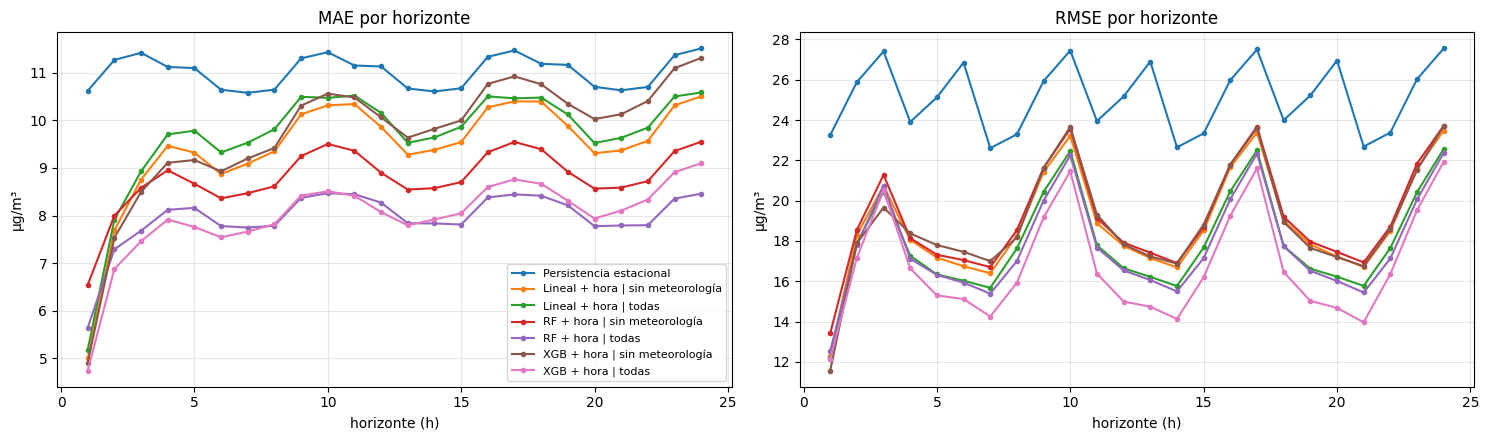

In [6]:
sel = ["Persistencia estacional",
       "Lineal + hora | sin meteorología", "Lineal + hora | todas",
       "RF + hora | sin meteorología",     "RF + hora | todas",
       "XGB + hora | sin meteorología",    "XGB + hora | todas"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
por_horizonte(T, sel, "MAE").plot(ax=ax[0], marker="o", ms=3, title="MAE por horizonte")
por_horizonte(T, sel, "RMSE").plot(ax=ax[1], marker="o", ms=3, title="RMSE por horizonte", legend=False)
for a in ax:
    a.set_xlabel("horizonte (h)"); a.set_ylabel("µg/m³"); a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Pronósticos contra el valor real
Ejemplos de pronósticos de 24 h desde cuatro orígenes: el que contiene el mayor pico del período evaluado y tres elegidos al azar con la semilla.

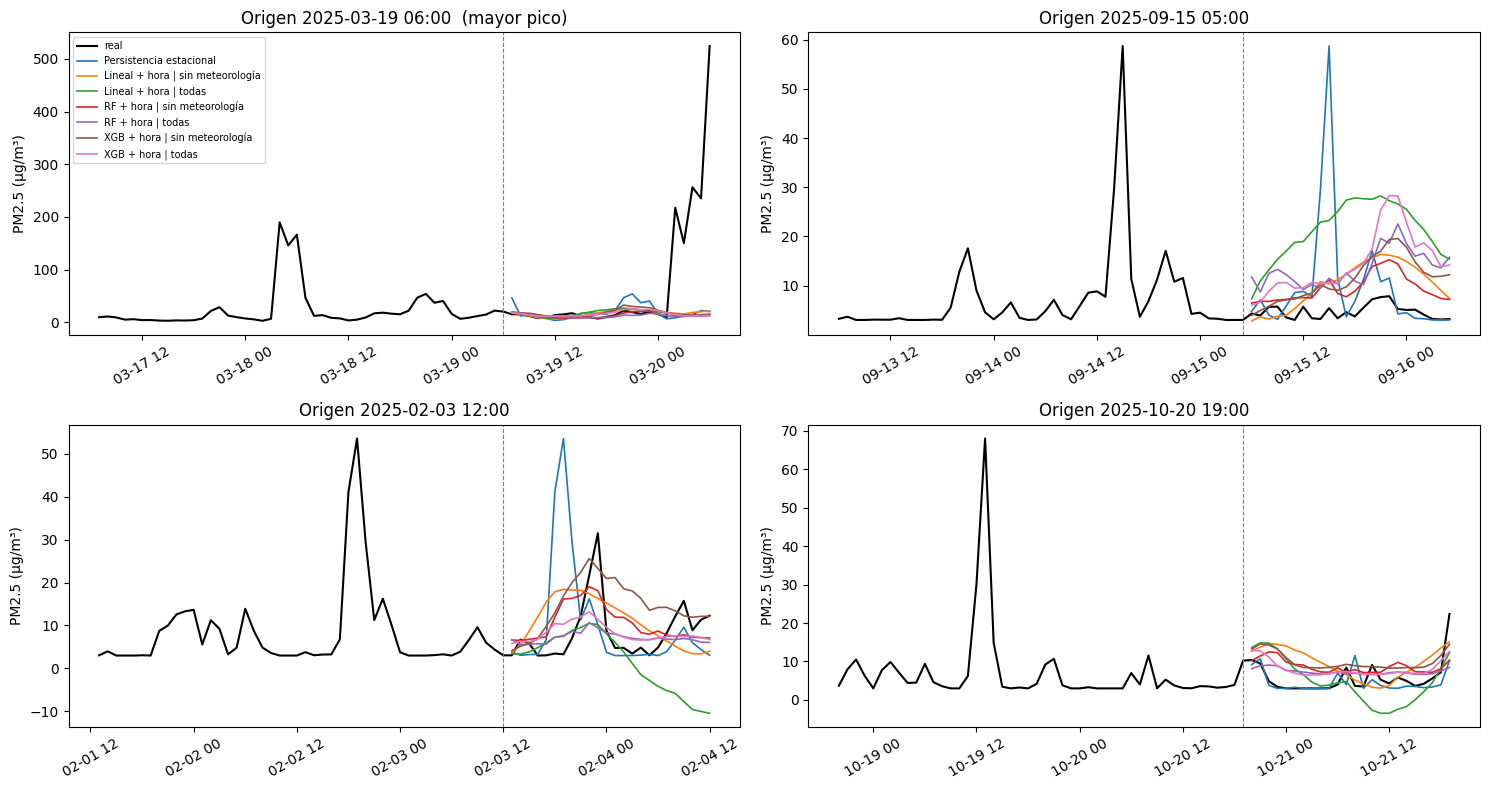

In [7]:
rng = np.random.default_rng(SEED)
ok = T.groupby("fold")["comun"].all()
folds_ok = ok[ok].index
f_pico = T[T["fold"].isin(folds_ok)].groupby("fold")["real"].max().idxmax()
elegidos = [f_pico] + list(rng.choice(folds_ok.drop(f_pico), 3, replace=False))

fig, axs = plt.subplots(2, 2, figsize=(15, 8))
for ax, f in zip(axs.flat, elegidos):
    seg = T[T["fold"] == f]
    origen = seg["origen"].iloc[0]
    ax.plot(y_real[origen - pd.Timedelta("47h"): seg.index[-1]], color="k", lw=1.5, label="real")
    for c in sel:
        ax.plot(seg[c], lw=1.2, label=c)
    ax.axvline(origen, color="gray", ls="--", lw=0.8)
    ax.set_title(f"Origen {origen:%Y-%m-%d %H:%M}" + ("  (mayor pico)" if f == f_pico else ""))
    ax.set_ylabel("PM2.5 (µg/m³)"); ax.tick_params(axis="x", labelrotation=30)
axs[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Aporte de cada variable en XGBoost

La prueba incremental de la sección 5 agrega las variables en un orden fijo y por grupos, por lo que no permite saber cuánto aporta cada una por separado. Para el modelo con mejor desempeño, XGBoost, se hace un estudio de ablación: se parte del modelo con todas las variables y se quita una por vez (o un grupo, como las dos componentes del viento), con los mismos folds y casos comunes. Si al quitar una variable el error sube, esa variable ayuda; si no cambia o baja, no está aportando.

Se usa este procedimiento y no la correlación porque, como señala la guía (10.2 y 10.4), una relación visual o una correlación no demuestran que una variable mejore el pronóstico; lo que importa es su efecto fuera del entrenamiento.

**Criterio, fijado antes de ver los resultados:** una variable es candidata a quitarse si al eliminarla el RMSE no aumenta (Δ RMSE ≤ 0). Como algunas variables están relacionadas entre sí (por ejemplo, la velocidad y las componentes del viento, o la temperatura y la humedad), quitar una puede no notarse porque la otra compensa. Por eso, la eliminación conjunta de las candidatas se confirma después con un nuevo backtesting.

In [8]:
GRUPOS = {"ninguna (todas)": [],
          "hora":            ["hora"],
          "velocidad":       ["velocidad_viento_ms"],
          "componentes u/v": ["viento_u", "viento_v"],
          "temperatura":     ["temperatura"],
          "humedad":         ["humedad"],
          "visibilidad":     ["visibilidad_km"]}

cfg = CONFIG["XGB"]
completo = pd.concat([cfg["hora"], meteo[METEO]], axis=1)

modelos_abl, exogs_abl = {}, {}
for g, columnas in GRUPOS.items():
    modelos_abl[g] = ForecasterRecursive(cfg["est"](), lags=cfg["lags"], dropna_from_series=True)
    exogs_abl[g] = completo.drop(columns=columnas)

preds_abl = backtest(modelos_abl, exogs_abl)
T_abl, cols_abl = tabla_comun(preds_abl)
res_abl = metricas(T_abl, cols_abl)
res_abl.index.name = "variable quitada"
for m in ("MAE", "RMSE"):
    res_abl[f"Δ {m}"] = (res_abl[m] - res_abl.loc["ninguna (todas)", m]).round(2)
res_abl.sort_values("Δ RMSE", ascending=False)

ninguna (todas): 26 s
hora: 26 s
velocidad: 26 s
componentes u/v: 27 s
temperatura: 26 s
humedad: 25 s
visibilidad: 23 s
Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE,Δ MAE,Δ RMSE
variable quitada,,,,
hora,8.44,17.98,0.46,0.99
velocidad,8.10,17.26,0.12,0.27
visibilidad,8.02,17.21,0.04,0.22
temperatura,7.94,17.12,-0.04,0.13
ninguna (todas),7.98,16.99,0.00,0.00
componentes u/v,8.02,16.98,0.04,-0.01
humedad,7.88,16.91,-0.10,-0.08


### 8.1 Confirmación del conjunto reducido
Se quitan juntas las variables candidatas y se compara el modelo reducido contra el modelo con todas las variables. Si el error no empeora, se adopta el conjunto reducido, por ser más simple.

In [10]:
#variables a quitar (candidatas con Δ RMSE ≤ 0)
QUITAR = ["viento_u", "viento_v", "humedad"]

modelos_red = {v: ForecasterRecursive(cfg["est"](), lags=cfg["lags"], dropna_from_series=True)
               for v in ("todas", "reducido")}
exogs_red = {"todas": completo, "reducido": completo.drop(columns=QUITAR)}

preds_red = backtest(modelos_red, exogs_red)
T_red, cols_red = tabla_comun(preds_red)
metricas(T_red, cols_red)

todas: 34 s
reducido: 25 s
Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE
todas,7.98,16.99
reducido,8.00,17.02


**Conclusión.** Al quitar juntas la humedad y las componentes del viento, el error aumenta levemente (MAE 8.00 frente a 7.98; RMSE 17.02 frente a 16.99). Aunque por separado ninguna de estas variables mostraba aporte, eliminarlas en conjunto empeora el pronóstico, lo que sugiere que se compensan entre sí. Según el criterio fijado, se mantiene el conjunto completo de variables meteorológicas. La diferencia es muy pequeña, por lo que la conclusión práctica es que el aporte de la meteorología se concentra en la velocidad del viento, la visibilidad y la temperatura, mientras que la humedad y la dirección del viento tienen un efecto marginal.

## 9. Ajuste de hiperparámetros de XGBoost con meteorología
Los hiperparámetros de XGBoost se eligieron en el notebook 04 sin variables meteorológicas. Como el modelo ahora tiene más variables de entrada, se repite una grilla pequeña alrededor de esa configuración (profundidad, tasa de aprendizaje y número de árboles), con el mismo protocolo y los mismos casos comunes. La grilla incluye la configuración actual, por lo que el resultado no puede empeorar, y se elige la combinación con menor RMSE.

### 9.1 Grilla pequeña alrededor de la configuración actual

In [11]:
from sklearn.model_selection import ParameterGrid

GRILLA = {"max_depth": [5, 7], "learning_rate": [0.01, 0.03], "n_estimators": [300, 600],
          "subsample": [0.8], "colsample_bytree": [0.8]}

ex_xgb = pd.concat([hora_int, meteo[METEO]], axis=1)
modelos_g, exogs_g, params_g = {}, {}, {}
for p in ParameterGrid(GRILLA):
    n = ", ".join(f"{k}={v}" for k, v in p.items() if k in ("max_depth", "learning_rate", "n_estimators"))
    params_g[n] = p
    modelos_g[n] = ForecasterRecursive(XGBRegressor(random_state=SEED, n_jobs=-1, **p),
                                       lags=CONFIG["XGB"]["lags"], dropna_from_series=True)
    exogs_g[n] = ex_xgb

preds_g = backtest(modelos_g, exogs_g)
T_g, cols_g = tabla_comun(preds_g)
res_g = metricas(T_g, cols_g).sort_values("RMSE")
display(res_g)

PARAMS_FINAL = params_g[res_g.index[0]]
PARAMS_FINAL

learning_rate=0.01, max_depth=5, n_estimators=300: 20 s
learning_rate=0.01, max_depth=5, n_estimators=600: 26 s
learning_rate=0.01, max_depth=7, n_estimators=300: 25 s
learning_rate=0.01, max_depth=7, n_estimators=600: 34 s
learning_rate=0.03, max_depth=5, n_estimators=300: 21 s
learning_rate=0.03, max_depth=5, n_estimators=600: 26 s
learning_rate=0.03, max_depth=7, n_estimators=300: 25 s
learning_rate=0.03, max_depth=7, n_estimators=600: 34 s
Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE
"learning_rate=0.01, max_depth=7, n_estimators=300",7.98,16.99
"learning_rate=0.01, max_depth=5, n_estimators=600",7.70,17.13
"learning_rate=0.03, max_depth=7, n_estimators=300",7.56,17.13
"learning_rate=0.03, max_depth=7, n_estimators=600",7.61,17.23
"learning_rate=0.01, max_depth=7, n_estimators=600",7.66,17.26
"learning_rate=0.01, max_depth=5, n_estimators=300",8.45,17.27
"learning_rate=0.03, max_depth=5, n_estimators=300",7.66,17.32
"learning_rate=0.03, max_depth=5, n_estimators=600",7.67,17.49


{'colsample_bytree': 0.8,
 'learning_rate': 0.01,
 'max_depth': 7,
 'n_estimators': 300,
 'subsample': 0.8}

**Interpretación.** La configuración elegida en el notebook 04 (`learning_rate=0.01`, `max_depth=7`, `n_estimators=300`) sigue siendo la de menor RMSE con las variables meteorológicas (16.99 µg/m³), por lo que se mantiene. Algunas combinaciones con mayor tasa de aprendizaje o más árboles obtienen un MAE menor (hasta 7.56), pero con un RMSE más alto (17.13 o más): aciertan mejor los valores típicos y peor los picos. Como el criterio principal es el RMSE, por su mayor sensibilidad a los errores en los episodios altos, no se adoptan.

## 10. Configuración final congelada

Con los resultados de los notebooks 04 y 06 se congela la configuración del modelo final (punto 16 de la metodología). A partir de este punto no se modifica ninguna decisión, y la evaluación en el período de test (2026) se hace en el notebook 07 sin reentrenar el modelo.

| Componente | Decisión | Dónde se decidió |
|---|---|---|
| Modelo | XGBoost | Notebook 06, sección 5 (menor RMSE) |
| Estrategia | Recursiva | Notebook 04, sección 7 |
| Rezagos | 1 a 24, 48 y 168 | Notebook 04, sección 8.2 |
| Hiperparámetros | `learning_rate=0.01`, `max_depth=7`, `n_estimators=300`, `subsample=0.8`, `colsample_bytree=0.8` | Notebook 04, sección 8.1; confirmados en notebook 06, sección 9 |
| Variables | Hora del día (entero), temperatura, humedad, velocidad del viento, componentes `viento_u` y

In [15]:
import json
from pathlib import Path

CONFIG_FINAL = {
    "modelo": "XGBRegressor",
    "estrategia": "recursiva",
    "lags": list(range(1, 25)) + [48, 168],
    "hiperparametros": {"learning_rate": 0.01, "max_depth": 7, "n_estimators": 300,
                        "subsample": 0.8, "colsample_bytree": 0.8},
    "semilla": SEED,
    "exog_calendario": ["hora"],
    "exog_meteo": METEO,
    "steps": STEPS,
    "interpolacion_max_horas": 3,
    "metrica_principal": "RMSE",
    "versiones": {"skforecast": skforecast.__version__, "sklearn": sklearn.__version__,
                  "xgboost": xgboost.__version__},
}
Path("configs").mkdir(exist_ok=True)
with open("configs/modelo_final.json", "w") as f:
    json.dump(CONFIG_FINAL, f, indent=2, ensure_ascii=False)
CONFIG_FINAL

{'modelo': 'XGBRegressor',
 'estrategia': 'recursiva',
 'lags': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  48,
  168],
 'hiperparametros': {'learning_rate': 0.01,
  'max_depth': 7,
  'n_estimators': 300,
  'subsample': 0.8,
  'colsample_bytree': 0.8},
 'semilla': 42,
 'exog_calendario': ['hora'],
 'exog_meteo': ['temperatura',
  'humedad',
  'velocidad_viento_ms',
  'viento_u',
  'viento_v',
  'visibilidad_km'],
 'steps': 24,
 'interpolacion_max_horas': 3,
 'metrica_principal': 'RMSE',
 'versiones': {'skforecast': '0.24.0', 'sklearn': '1.6.1', 'xgboost': '3.4.1'}}

In [16]:
from google.colab import files
files.download("configs/modelo_final.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>